# Clash of Clans clan wars: exploration

Six questions about the data collected by the pipeline. Under each plot, write one sentence about what you actually see. Those sentences become the Key findings in the README.

In [2]:
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

db = sqlite3.connect(ROOT / "data" / "wars.db")
TIME_FMT = "%Y%m%dT%H%M%S.%fZ"

rows = []
for war_key, state, snapshot in db.execute("SELECT war_key, state, snapshot FROM wars"):
    w = json.loads(snapshot)
    a, b = sorted([w["clan"], w["opponent"]], key=lambda c: c["tag"])
    rows.append({
        "war_key": war_key,
        "state": state,
        "team_size": w["teamSize"],
        "end_time": pd.to_datetime(w["endTime"], format=TIME_FMT, utc=True),
        "stars_a": a["stars"], "stars_b": b["stars"],
        "dest_a": a["destructionPercentage"], "dest_b": b["destructionPercentage"],
    })
wars = pd.DataFrame(rows)
ended = wars[wars["state"] == "warEnded"].copy()
ended["draw"] = (ended["stars_a"] == ended["stars_b"]) & (ended["dest_a"] == ended["dest_b"])
ended["perfect_draw"] = ended["draw"] & (ended["dest_a"] == 100.0)
print(f"{len(wars)} wars stored, {len(ended)} ended")

1412 wars stored, 504 ended


## 1. How common are draws, and does team size matter?

Draws: 26.2% | both clans at 100%: 26.2%
           count      mean
team_size                 
5             42  0.071429
10            59  0.050847
15            80  0.100000
20            80  0.275000
25            54  0.240741
30            58  0.224138
35            41  0.463415
40            32  0.656250
45            38  0.578947
50            18  0.388889


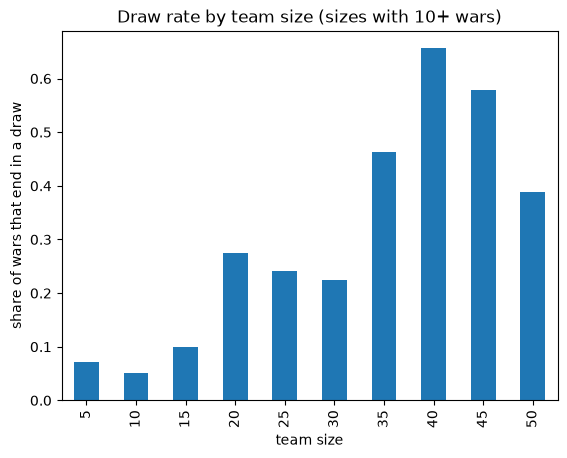

In [3]:
print(f"Draws: {ended['draw'].mean():.1%} | both clans at 100%: {ended['perfect_draw'].mean():.1%}")
by_size = ended.groupby("team_size")["draw"].agg(["count", "mean"])
by_size = by_size[by_size["count"] >= 10]
print(by_size)

by_size["mean"].plot.bar()
plt.ylabel("share of wars that end in a draw")
plt.xlabel("team size")
plt.title("Draw rate by team size (sizes with 10+ wars)")
plt.show()

## 2. How closely does matchmaking pair clans?

Wars with |TH average difference| < 0.25: 58.7%


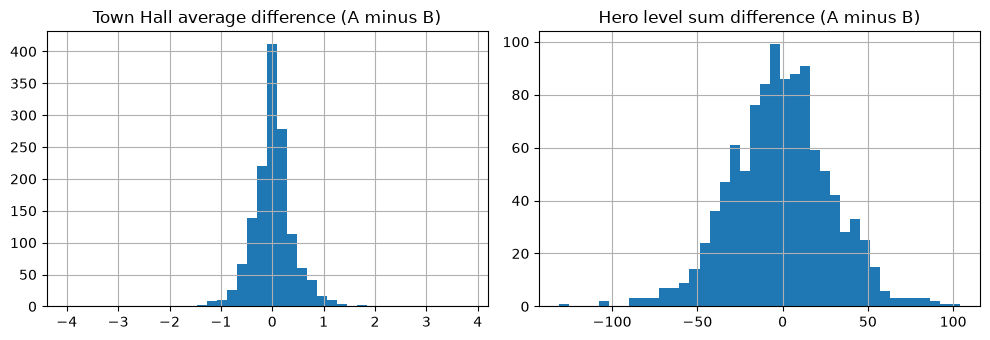

In [4]:
f1 = pd.read_csv(ROOT / "data" / "features.csv")
f2 = pd.read_csv(ROOT / "data" / "features_players.csv")

print(f"Wars with |TH average difference| < 0.25: {(f1['th_avg_diff'].abs() < 0.25).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
f1["th_avg_diff"].hist(bins=40, ax=axes[0])
axes[0].set_title("Town Hall average difference (A minus B)")
f2["hero_sum_diff"].hist(bins=40, ax=axes[1])
axes[1].set_title("Hero level sum difference (A minus B)")
plt.tight_layout()
plt.show()

## 3. Does the stronger clan (by hero levels) win more often?

                    count      mean        se
gap_bin                                      
(-75.101, -27.048]     56  0.428571  0.066130
(-27.048, -12.24]      55  0.509091  0.067409
(-12.24, 4.18]         55  0.527273  0.067320
(4.18, 22.427]         55  0.600000  0.066058
(22.427, 104.0]        56  0.571429  0.066130


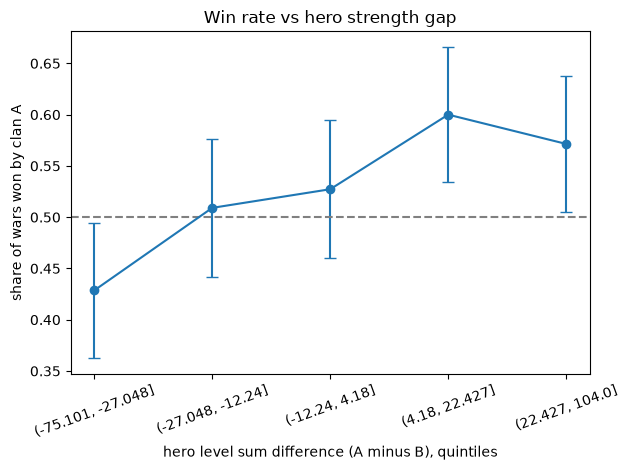

In [5]:
d = f1.merge(f2, on="war_key")
d = d[d["label"].notna()].copy()
d["gap_bin"] = pd.qcut(d["hero_sum_diff"], 5)
g = d.groupby("gap_bin", observed=True)["label"].agg(["count", "mean"])
g["se"] = np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"])
print(g)

plt.errorbar(range(len(g)), g["mean"], yerr=g["se"], fmt="o-", capsize=4)
plt.axhline(0.5, color="gray", linestyle="--")
plt.xticks(range(len(g)), g.index.astype(str), rotation=20)
plt.ylabel("share of wars won by clan A")
plt.xlabel("hero level sum difference (A minus B), quintiles")
plt.title("Win rate vs hero strength gap")
plt.tight_layout()
plt.show()

## 4. Who earns the stars: top, middle or bottom of the map?

                      stars  destruction
attacker_position                       
top third          2.549417    91.087512
middle third       2.503950    90.082957
bottom third       2.402165    86.511559
(31895 attacks)


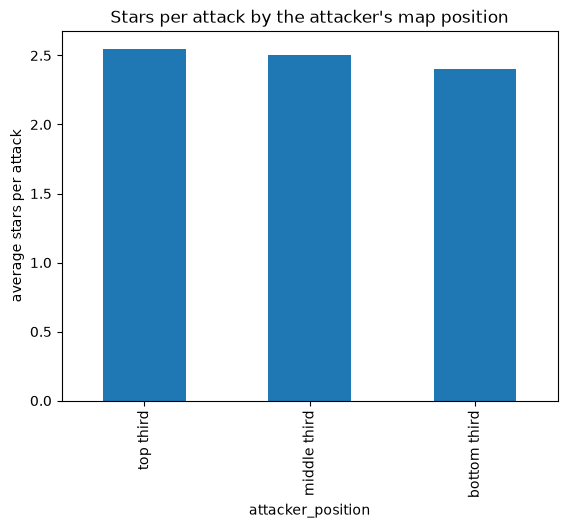

In [6]:
atk_rows = []
for (snapshot,) in db.execute("SELECT snapshot FROM wars WHERE state = 'warEnded'"):
    w = json.loads(snapshot)
    n = w["teamSize"]
    for side in (w["clan"], w["opponent"]):
        for m in side.get("members", []):
            for atk in m.get("attacks", []):
                atk_rows.append({
                    "rel_pos": m["mapPosition"] / n,
                    "stars": atk["stars"],
                    "destruction": atk["destructionPercentage"],
                })
atk = pd.DataFrame(atk_rows)
atk["attacker_position"] = pd.cut(
    atk["rel_pos"], [0, 1 / 3, 2 / 3, 1.0],
    labels=["top third", "middle third", "bottom third"],
)
summary = atk.groupby("attacker_position", observed=True)[["stars", "destruction"]].mean()
print(summary)
print(f"({len(atk)} attacks)")

summary["stars"].plot.bar()
plt.ylabel("average stars per attack")
plt.title("Stars per attack by the attacker's map position")
plt.show()

## 5. How maxed are heroes at each Town Hall level?

      count       25%       50%       75%
th                                       
8     371.0  0.050000  0.090909  0.095455
9     732.0  0.079625  0.119936  0.183573
10    908.0  0.144657  0.208931  0.257576
11   1521.0  0.180542  0.259900  0.316359
12   1832.0  0.270877  0.365044  0.418240
13   3737.0  0.350577  0.439572  0.503766
14   3576.0  0.443040  0.556986  0.608242
15   5595.0  0.456550  0.565558  0.639862
16   5903.0  0.491889  0.640228  0.722847
17   8040.0  0.607451  0.744461  0.821319
18  28272.0  0.807079  0.940989  1.000000


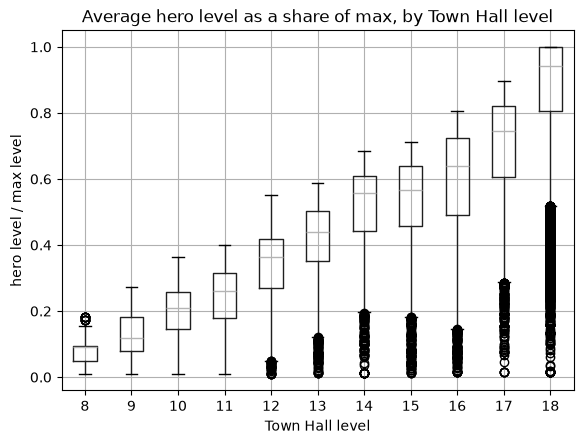

In [7]:
recs = []
for (data,) in db.execute("SELECT data FROM players"):
    p = json.loads(data)
    fr = [h[0] / h[1] for h in (p.get("heroes") or {}).values() if h[1]]
    recs.append({"th": p.get("th"), "hero_frac": np.mean(fr) if fr else np.nan})
pl = pd.DataFrame(recs).dropna()
pl = pl.groupby("th").filter(lambda g: len(g) >= 200)
print(pl.groupby("th")["hero_frac"].describe()[["count", "25%", "50%", "75%"]])

pl.boxplot(column="hero_frac", by="th")
plt.suptitle("")
plt.title("Average hero level as a share of max, by Town Hall level")
plt.xlabel("Town Hall level")
plt.ylabel("hero level / max level")
plt.show()

# Note: the same player can appear in several wars, so rows are not independent.

## 6. How many final results did the collector miss?

In [8]:
ref = pd.Timestamp(db.execute("SELECT MAX(updated_at) FROM wars").fetchone()[0], tz="UTC")
over = wars[wars["end_time"] < ref - pd.Timedelta(hours=6)]
missed = over[over["state"] != "warEnded"]
print(f"Wars whose end time passed 6+ hours before the last update: {len(over)}")
print(f"...of which never recorded as 'warEnded': {len(missed)} ({len(missed) / len(over):.1%})")
print(missed["state"].value_counts())

Wars whose end time passed 6+ hours before the last update: 1350
...of which never recorded as 'warEnded': 846 (62.7%)
state
inWar          845
preparation      1
Name: count, dtype: int64
